# Módulo IV – Aprendizado de Máquina · Aula 2: classificação e regressão
**Execução e interpretações de: Arthur Rodrigues de Souza Vieira** — Sistemas de Informação — UDF

Profa. Kadidja Valéria | UDF | Sistemas de Informação | 2026.2

Este caderno reproduz o [notebook didático da professora](laboratorio.ipynb) sem alterar o código-base (mesma simulação, semente 42, mesma divisão e mesma regra de escolha da árvore). O que acrescentei: células de interpretação, os seis exercícios de investigação resolvidos em código e três experimentos meus, pensados a partir do que faço no projeto da disciplina (desenvolvimento de um sistema web com painel de indicadores): **(a)** o efeito da estratégia de imputação e do vazamento na imputação, **(b)** poda por custo-complexidade (`ccp_alpha`) e **(c)** quantas regras um sistema precisaria implementar para chegar perto da árvore completa.

Todos os registros são **sintéticos**; as relações foram definidas pela simulação e não são evidência sobre estudantes reais.

O caderno roda no Jupyter (de dentro de `notebooks/`) e no Colab (Ambiente de execução › Executar tudo). As figuras vão para `../assets/` quando essa pasta existe; no Colab, para `./assets/`. O CSV é lido de `../dados/` ou, na falta dele, do GitHub.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score,
                             mean_absolute_error, r2_score)
SEMENTE = 42

PASTA_ASSETS = '../assets' if os.path.isdir('../assets') else './assets'
os.makedirs(PASTA_ASSETS, exist_ok=True)
def salvar(nome):
    caminho = os.path.join(PASTA_ASSETS, nome)
    plt.savefig(caminho, dpi=120, bbox_inches='tight')
    print('figura gravada em', caminho)

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__,
      '| matplotlib:', matplotlib.__version__, '| scikit-learn:', sklearn.__version__)

Python: 3.13.18
NumPy: 2.5.3 | pandas: 3.0.5 | matplotlib: 3.11.2 | scikit-learn: 1.9.1


## 1. Dados e pergunta de negócio
Pergunta: ao fim da **semana 4**, com frequência, nota parcial e entregas, quais estudantes fictícios deveriam ser procurados primeiro pela equipe de apoio com um convite voluntário? Alvo: `evasao_fim_semestre` (0 = permaneceu, 1 = evadiu), que só existe no fim do semestre. Unidade de análise: um estudante fictício.

Gero os dados com a simulação da professora e confiro se batem com o CSV distribuído em `dados/` (ou com a cópia no GitHub, no Colab).

In [2]:
rng = np.random.default_rng(SEMENTE)
n = 600
frequencia = rng.uniform(35, 100, n)
nota = rng.uniform(0, 10, n)
entregas = rng.integers(0, 9, n)
logit = -0.4 + (65 - frequencia)/18 + (5 - nota)/2 + (4 - entregas)/3
prob_simulada = 1 / (1 + np.exp(-logit))
alvo = rng.binomial(1, prob_simulada)
dados = pd.DataFrame({'frequencia_sem4': frequencia,
                      'nota_sem4': nota, 'entregas_sem4': entregas,
                      'evasao_fim_semestre': alvo})
dados.loc[rng.choice(n, 30, replace=False), 'nota_sem4'] = np.nan

FONTES_CSV = ['../dados/educacionais-sinteticos.csv',
              'https://raw.githubusercontent.com/arthur2012sousa40-code/Ciencia_Dados_Aprendizagem_Maquina/main/Aprendizado_de_Maquina/Aprendizado%20de%20m%C3%A1quina/dados/educacionais-sinteticos.csv']
csv_igual = None
for fonte in FONTES_CSV:
    try:
        csv = pd.read_csv(fonte)
        csv_igual = bool(np.allclose(csv.fillna(-1).values, dados.fillna(-1).values))
        print('CSV lido de', fonte, '| igual à simulação?', csv_igual)
        break
    except Exception as erro:
        print('não li', fonte, '-', type(erro).__name__)

print(dados.head().round(2).to_string(index=False))
print('Dimensões:', dados.shape)
print('Ausentes por coluna:', dados.isna().sum().to_dict())
print('Classes (%):', dados['evasao_fim_semestre'].value_counts(normalize=True).mul(100).round(1).to_dict())

CSV lido de ../dados/educacionais-sinteticos.csv | igual à simulação? True
 frequencia_sem4  nota_sem4  entregas_sem4  evasao_fim_semestre
           85.31       4.78              0                    1
           63.53       7.61              5                    1
           90.81       9.03              6                    0
           80.33       7.21              4                    0
           41.12       9.63              3                    1
Dimensões: (600, 4)
Ausentes por coluna: {'frequencia_sem4': 0, 'nota_sem4': 30, 'entregas_sem4': 0, 'evasao_fim_semestre': 0}
Classes (%): {0: 59.0, 1: 41.0}


## 2. Separação antes de aprender qualquer transformação
Holdout estratificado 75/25 com semente 42. Daqui até a avaliação final, só o treino é usado. Como exploração própria (apenas no treino), olho a taxa de evasão por faixa de frequência, porque é o tipo de corte que um painel mostraria.

Treino: 450 | Teste: 150
Proporção de evasão: treino 0.411 | teste 0.407
       frequencia_sem4  nota_sem4  entregas_sem4
count           450.00     427.00         450.00
mean             67.19       5.13           4.10
std              18.66       2.91           2.65
min              35.48       0.01           0.00
25%              50.54       2.55           2.00
50%              67.27       5.15           4.00
75%              83.53       7.73           7.00
max              99.94       9.99           8.00

Taxa de evasão no treino por faixa de frequência:
                  taxa    n
frequencia_sem4            
35-50%           0.541  109
50-65%           0.562   96
65-80%           0.360  111
80-100%          0.239  134


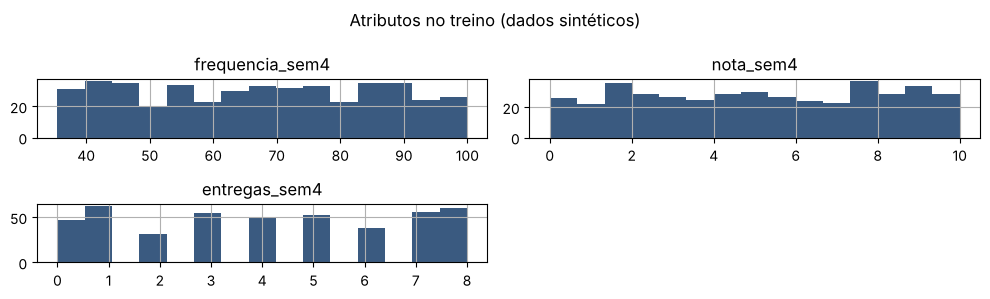

In [3]:
atributos = ['frequencia_sem4', 'nota_sem4', 'entregas_sem4']
X = dados[atributos]
y = dados['evasao_fim_semestre']
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE)
print('Treino:', len(X_treino), '| Teste:', len(X_teste))
print('Proporção de evasão: treino %.3f | teste %.3f' % (y_treino.mean(), y_teste.mean()))
print(X_treino.describe().round(2))

faixa_freq = pd.cut(X_treino['frequencia_sem4'], bins=[0, 50, 65, 80, 100],
                    labels=['35-50%', '50-65%', '65-80%', '80-100%'])
print('\nTaxa de evasão no treino por faixa de frequência:')
print(y_treino.groupby(faixa_freq, observed=True).agg(taxa='mean', n='size').round(3).to_string())

X_treino.hist(figsize=(10, 3), bins=15, color='#3a5a80')
plt.suptitle('Atributos no treino (dados sintéticos)')
plt.tight_layout(); plt.show()

**Leitura (resultado calculado no treino):** o CSV distribuído é idêntico à simulação; 30 notas ausentes (5%), 59% de permanência e 41% de evasão, proporção mantida nos dois conjuntos pela estratificação (0,411 no treino, 0,407 no teste). Nas faixas de frequência, a taxa de evasão cai de cerca de 54–56% (abaixo de 65%) para 36% (65–80%) e 24% (acima de 80%). Isso é só uma descrição do treino: a tabela sugere um corte perto de 65%, e é exatamente o que vou conferir na árvore. Como a simulação definiu essa relação, não é evidência sobre estudantes reais.

## 3. Escolha da árvore somente no treino
Sigo exatamente o roteiro da professora: profundidades 2, 3, 5 e `None`, com `min_samples_leaf=10`, comparadas por validação cruzada estratificada em cinco partes do treino; a imputação pela mediana fica dentro do `Pipeline` e é reaprendida em cada dobra. A regra de escolha é a do roteiro (maior acurácia média de validação) e eu a fixei **antes** de rodar a grade do exercício 1, que vem logo abaixo.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

def arvore(profundidade, folha=10, **extra):
    return Pipeline([('imputador', SimpleImputer(strategy='median')),
                     ('arvore', DecisionTreeClassifier(max_depth=profundidade, min_samples_leaf=folha,
                                                       random_state=SEMENTE, **extra))])

def avaliar_cv(pipeline, X_=None, y_=None):
    s = cross_validate(pipeline, X_treino if X_ is None else X_, y_treino if y_ is None else y_,
                       cv=cv, scoring='accuracy', return_train_score=True)
    return s['train_score'].mean(), s['test_score'].mean(), s['test_score'].std()

comparacao = []
for profundidade in [2, 3, 5, None]:
    tr, va, sd = avaliar_cv(arvore(profundidade))
    comparacao.append({'profundidade': str(profundidade), 'acuracia_treino_cv': tr,
                       'acuracia_validacao_cv': va, 'desvio_validacao_cv': sd, 'distancia': tr - va})
comparacao = pd.DataFrame(comparacao)
print(comparacao.round(4).to_string(index=False))
melhor = comparacao.sort_values('acuracia_validacao_cv', ascending=False, kind='stable').iloc[0]
prof = None if melhor['profundidade'] == 'None' else int(melhor['profundidade'])
modelo = arvore(prof)
modelo.fit(X_treino, y_treino)
print('Profundidade escolhida somente no treino:', prof)

profundidade  acuracia_treino_cv  acuracia_validacao_cv  desvio_validacao_cv  distancia
           2              0.7328                 0.6844               0.0425     0.0483
           3              0.7678                 0.7022               0.0257     0.0656
           5              0.8111                 0.7222               0.0391     0.0889
        None              0.8206                 0.7111               0.0477     0.1094
Profundidade escolhida somente no treino: 5


### Exercício 1 (antes de abrir o teste): `min_samples_leaf` = 5, 20 e 40
Acrescento as folhas 5, 20 e 40 à comparação, cruzadas com as mesmas profundidades. Registro média, desvio e distância treino–validação (exercício 2).

In [5]:
grade = []
for folha in [5, 10, 20, 40]:
    for profundidade in [2, 3, 5, None]:
        tr, va, sd = avaliar_cv(arvore(profundidade, folha))
        grade.append({'folha': folha, 'profundidade': str(profundidade), 'treino_cv': tr,
                      'validacao_cv': va, 'desvio': sd, 'distancia': tr - va})
grade = pd.DataFrame(grade)
print(grade.round(4).to_string(index=False))
topo = grade.loc[grade['validacao_cv'].idxmax()]
print('\nMaior média de validação da grade: folha %d, profundidade %s -> %.4f ± %.4f'
      % (topo['folha'], topo['profundidade'], topo['validacao_cv'], topo['desvio']))
dentro = grade[grade['validacao_cv'] >= topo['validacao_cv'] - topo['desvio']]
print('Configurações a menos de um desvio da melhor: %d de %d' % (len(dentro), len(grade)))
print('Modelo do roteiro (folha 10, profundidade %s): %.4f ± %.4f'
      % (prof, melhor['acuracia_validacao_cv'], melhor['desvio_validacao_cv']))

 folha profundidade  treino_cv  validacao_cv  desvio  distancia
     5            2     0.7328        0.6844  0.0425     0.0483
     5            3     0.7706        0.7000  0.0233     0.0706
     5            5     0.8261        0.7222  0.0298     0.1039
     5         None     0.8678        0.7133  0.0215     0.1544
    10            2     0.7328        0.6844  0.0425     0.0483
    10            3     0.7678        0.7022  0.0257     0.0656
    10            5     0.8111        0.7222  0.0391     0.0889
    10         None     0.8206        0.7111  0.0477     0.1094
    20            2     0.7328        0.6844  0.0425     0.0483
    20            3     0.7656        0.6978  0.0325     0.0678
    20            5     0.7900        0.7267  0.0480     0.0633
    20         None     0.7900        0.7267  0.0480     0.0633
    40            2     0.7328        0.6844  0.0425     0.0483
    40            3     0.7661        0.7111  0.0351     0.0550
    40            5     0.7756        0.

**Leitura da grade (exercícios 1 e 2):** a maior média é da folha 40 com profundidade 5 ou `None` (0,7289 ± 0,0303), mas 11 das 16 combinações ficam a menos de um desvio dessa melhor, inclusive o modelo do roteiro (folha 10, profundidade 5: 0,7222 ± 0,0391). Ou seja, dentro da incerteza da validação cruzada, as configurações são indistinguíveis; o que a grade mostra com clareza é outra coisa: a **distância treino–validação**. Ela vai de 0,154 (folha 5 sem limite de profundidade: 0,868 de treino para 0,713 de validação) a 0,047 (folha 40). Folhas pequenas e árvore funda ajustam o treino muito melhor sem generalizar melhor, que é a assinatura do sobreajuste.

Mantenho o modelo do roteiro porque a regra de escolha foi fixada antes da grade. Se eu trocasse para folha 40 agora, por um ganho de 0,007 (menor que o desvio), estaria escolhendo pelo ruído da divisão em dobras. Numa aplicação real, eu preferiria folhas maiores pela estabilidade, mas isso teria de ser decidido antes de abrir o teste.

## 4. Avaliação final em dados não vistos
O teste é usado uma única vez, com o modelo escolhido no roteiro (`max_depth=5`, `min_samples_leaf=10`). Além da acurácia e da matriz, calculo a sensibilidade, a precisão e o F1 da classe 1, e confiro a acurácia à mão a partir da matriz (exercício 3).

Acurácia treino: 0.8133
Acurácia teste: 0.7800; referência (classe mais frequente): 0.5933
Matriz [linhas reais, colunas previstas]:
 [[75 14]
 [19 42]]
TN: 75 FP: 14 FN: 19 TP: 42
Acurácia à mão: (75 + 42) / 150 = 0.7800
Sensibilidade classe 1: 42/61 = 0.6885 | precisão: 42/56 = 0.7500 | especificidade: 0.8427
F1 classe 1 (sklearn): 0.7179 | recall (sklearn): 0.6885
Referência: sensibilidade = 0.0 (nunca prevê 1)
figura gravada em ../assets/matriz-confusao.png


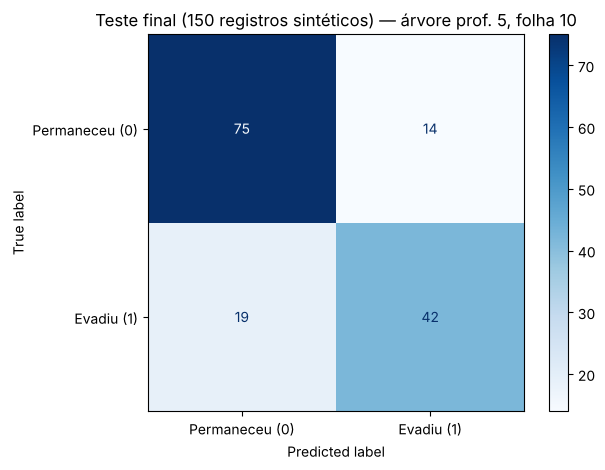

In [6]:
prev = modelo.predict(X_teste)
base = DummyClassifier(strategy='most_frequent').fit(X_treino, y_treino)
acc = accuracy_score(y_teste, prev)
acc_base = accuracy_score(y_teste, base.predict(X_teste))
cm = confusion_matrix(y_teste, prev, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
acc_treino = modelo.score(X_treino, y_treino)
print(f'Acurácia treino: {acc_treino:.4f}')
print(f'Acurácia teste: {acc:.4f}; referência (classe mais frequente): {acc_base:.4f}')
print('Matriz [linhas reais, colunas previstas]:\n', cm)
print('TN:', tn, 'FP:', fp, 'FN:', fn, 'TP:', tp)
acc_manual = (tn + tp) / cm.sum()
print(f'Acurácia à mão: ({tn} + {tp}) / {cm.sum()} = {acc_manual:.4f}')
sens = tp / (tp + fn); prec = tp / (tp + fp); espec = tn / (tn + fp)
print(f'Sensibilidade classe 1: {tp}/{tp+fn} = {sens:.4f} | precisão: {tp}/{tp+fp} = {prec:.4f} | especificidade: {espec:.4f}')
print('F1 classe 1 (sklearn): %.4f | recall (sklearn): %.4f' % (f1_score(y_teste, prev), recall_score(y_teste, prev)))
print('Referência: sensibilidade = %.1f (nunca prevê 1)' % recall_score(y_teste, base.predict(X_teste)))

ConfusionMatrixDisplay(cm, display_labels=['Permaneceu (0)', 'Evadiu (1)']).plot(cmap='Blues')
plt.title('Teste final (150 registros sintéticos) — árvore prof. 5, folha 10')
plt.tight_layout(); salvar('matriz-confusao.png'); plt.show()

figura gravada em ../assets/arvore.png


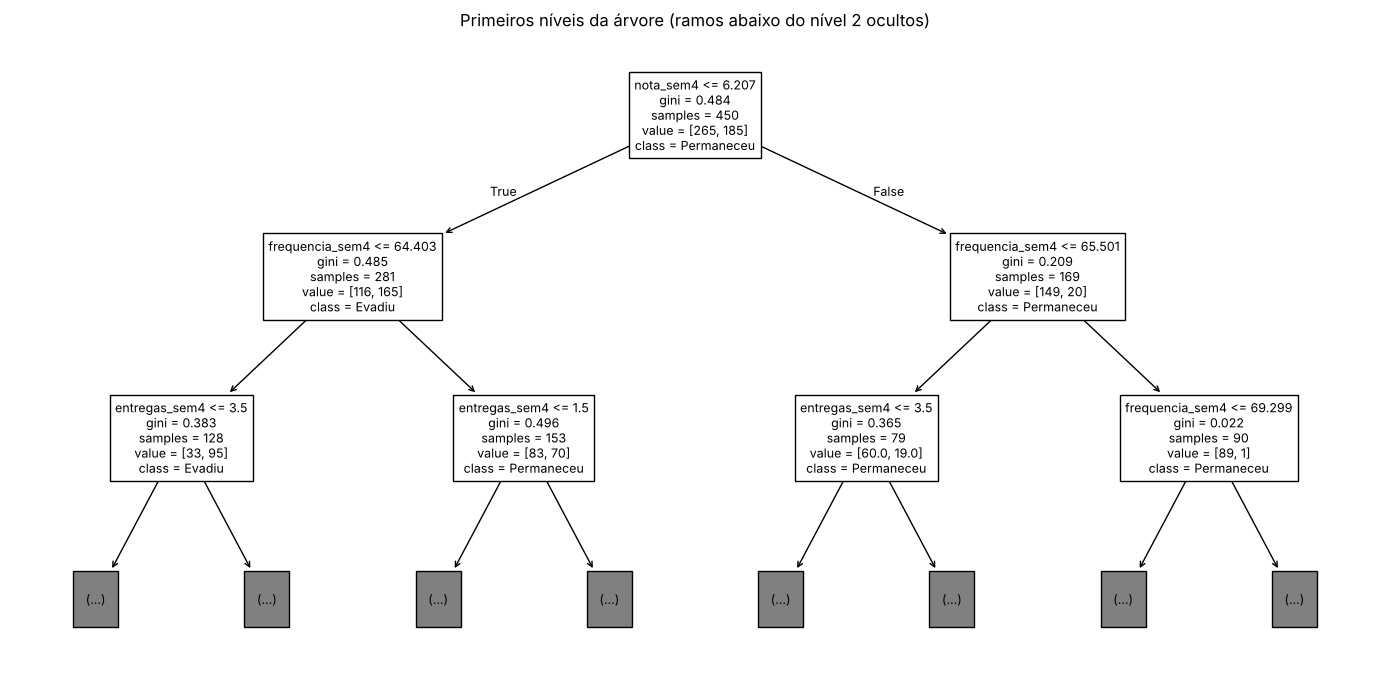

Profundidade real da árvore: 5 | folhas: 21
Importância dos atributos: {'frequencia_sem4': np.float64(0.235), 'nota_sem4': np.float64(0.622), 'entregas_sem4': np.float64(0.143)}
|--- nota_sem4 <= 6.21
|   |--- frequencia_sem4 <= 64.40
|   |   |--- entregas_sem4 <= 3.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- entregas_sem4 >  3.50
|   |   |   |--- truncated branch of depth 3
|   |--- frequencia_sem4 >  64.40
|   |   |--- entregas_sem4 <= 1.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- entregas_sem4 >  1.50
|   |   |   |--- truncated branch of depth 3
|--- nota_sem4 >  6.21
|   |--- frequencia_sem4 <= 65.50
|   |   |--- entregas_sem4 <= 3.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- entregas_sem4 >  3.50
|   |   |   |--- truncated branch of depth 3
|   |--- frequencia_sem4 >  65.50
|   |   |--- frequencia_sem4 <= 69.30
|   |   |   |--- class: 0
|   |   |--- frequencia_sem4 >  69.30
|   |   |   |--- class: 0



In [7]:
arv = modelo.named_steps['arvore']
plt.figure(figsize=(14, 7))
plot_tree(arv, feature_names=atributos, class_names=['Permaneceu', 'Evadiu'],
          max_depth=2, filled=False, fontsize=9)
plt.title('Primeiros níveis da árvore (ramos abaixo do nível 2 ocultos)')
plt.tight_layout(); salvar('arvore.png'); plt.show()
print('Profundidade real da árvore:', arv.get_depth(), '| folhas:', arv.get_n_leaves())
print('Importância dos atributos:', dict(zip(atributos, arv.feature_importances_.round(3))))
print(export_text(arv, feature_names=atributos, max_depth=2, decimals=2))

**Resultado calculado (teste, 150 registros, usado uma só vez):** acurácia 0,7800 contra 0,5933 da referência que sempre prevê permanência. Conferência manual: (75 + 42) / 150 = 0,78. Matriz: TN = 75, FP = 14, FN = 19, TP = 42. Sensibilidade da classe 1 = 42/61 = 0,689; precisão = 42/56 = 0,75; especificidade = 75/89 = 0,843; F1 = 0,718. Treino 0,8133 e validação 0,7222 ± 0,0391: o teste caiu dentro da faixa esperada, um pouco acima da média de validação, o que é compatível com a variação entre dobras e não indica nada de especial.

**Interpretação dos erros:** os 19 falsos negativos são estudantes que evadiram e não seriam sinalizados (31% da evasão do teste); os 14 falsos positivos receberiam um convite sem precisar. Como a ação é um convite voluntário, o custo do falso positivo é pequeno (tempo da equipe e algum incômodo), e o do falso negativo é maior (ninguém procura quem precisava). A referência tem sensibilidade zero: acerta 59% só por nunca apontar evasão. É por isso que acurácia sozinha não serve para aprovar um modelo.

**Árvore:** a raiz pergunta `nota_sem4 ≤ 6,21`; nos dois ramos a pergunta seguinte é sobre frequência (64,4% e 65,5%), o mesmo corte que apareceu na minha tabela por faixas. Importância: nota 0,622, frequência 0,235, entregas 0,143. A árvore completa tem 21 folhas em 5 níveis. Importância mede utilidade para separar as classes nesta simulação, não causa.

## 5. Previsão de registros fictícios
O caso da professora e mais três perfis que inventei para ver como a árvore reage quando um sinal é bom e outro é ruim. A estimativa é a frequência de evasão na folha em que o registro cai, não uma probabilidade garantida.

In [8]:
novos = pd.DataFrame({'frequencia_sem4': [72.0, 95.0, 45.0, 60.0],
                      'nota_sem4': [6.0, 3.0, 8.5, np.nan],
                      'entregas_sem4': [5, 2, 7, 4]})
indice_1 = list(arv.classes_).index(1)
classe_prevista = modelo.predict(novos)
estimativa = modelo.predict_proba(novos)[:, indice_1].round(3)
novos['classe_prevista'] = classe_prevista
novos['estimativa_evasao'] = estimativa
novos.insert(0, 'perfil', ['roteiro da professora', 'frequenta, mas nota baixa',
                           'nota alta, frequência baixa', 'nota ausente (imputada)'])
print(novos.to_string(index=False))
print('Mediana aprendida no treino para nota_sem4:', modelo.named_steps['imputador'].statistics_[1].round(3))

                     perfil  frequencia_sem4  nota_sem4  entregas_sem4  classe_prevista  estimativa_evasao
      roteiro da professora             72.0        6.0              5                0              0.342
  frequenta, mas nota baixa             95.0        3.0              2                0              0.171
nota alta, frequência baixa             45.0        8.5              7                0              0.000
    nota ausente (imputada)             60.0        NaN              4                0              0.455
Mediana aprendida no treino para nota_sem4: 5.146


**Leitura:** o caso do roteiro (72%, nota 6, 5 entregas) cai numa folha com 34% de evasão e é classificado como permanência. O perfil "frequenta, mas nota baixa" (95%, nota 3) recebe 17%; o perfil "nota alta, frequência baixa" (45%, nota 8,5, 7 entregas) cai numa folha sem nenhuma evasão no treino (0,0). O perfil com nota ausente recebe a mediana do treino (5,146) e fica em 45,5%, o caso mais incerto dos quatro. Esses números são frequências de folhas com poucas dezenas de registros; uma estimativa 0,0 não significa risco zero, só que ninguém daquela folha evadiu nos 450 registros de treino. Se o sistema mostrasse isso a uma equipe, deveria mostrar como "sem casos observados", não como certeza.

## 6. Exercícios de investigação em código
### Exercício 4 — retirar um atributo (validação cruzada no treino)

In [9]:
linhas = []
tr, va, sd = avaliar_cv(arvore(prof))
linhas.append({'atributos': 'todos', 'validacao_cv': va, 'desvio': sd, 'treino_cv': tr})
for retirado in atributos:
    restantes = [a for a in atributos if a != retirado]
    tr, va, sd = avaliar_cv(arvore(prof), X_treino[restantes], y_treino)
    linhas.append({'atributos': 'sem ' + retirado, 'validacao_cv': va, 'desvio': sd, 'treino_cv': tr})
ablacao = pd.DataFrame(linhas)
ablacao['queda'] = ablacao['validacao_cv'] - ablacao.loc[0, 'validacao_cv']
print(ablacao.round(4).to_string(index=False))

          atributos  validacao_cv  desvio  treino_cv   queda
              todos        0.7222  0.0391     0.8111  0.0000
sem frequencia_sem4        0.7156  0.0362     0.7789 -0.0067
      sem nota_sem4        0.6289  0.0475     0.7311 -0.0933
  sem entregas_sem4        0.7022  0.0310     0.7911 -0.0200


### Exercício 5 — se 95% permanecessem
Calculo o que a referência faria em um teste hipotético de 200 registros com 190 permanências e 10 evasões (cenário inventado para o exercício, não são os dados do laboratório).

In [10]:
y_hip = np.array([0]*190 + [1]*10)
prev_hip = np.zeros_like(y_hip)          # sempre prevê permanência
cm_hip = confusion_matrix(y_hip, prev_hip, labels=[0, 1])
print('Acurácia de sempre prever permanência: %.3f' % accuracy_score(y_hip, prev_hip))
print('Matriz hipotética [reais x previstas]:\n', cm_hip)
print('Sensibilidade da classe 1: %.1f | falsos negativos: %d (toda a evasão)' % (recall_score(y_hip, prev_hip), cm_hip[1, 0]))

Acurácia de sempre prever permanência: 0.950
Matriz hipotética [reais x previstas]:
 [[190   0]
 [ 10   0]]
Sensibilidade da classe 1: 0.0 | falsos negativos: 10 (toda a evasão)


**Leitura (cenário hipotético):** com 95% de permanência, prever sempre "permaneceu" dá 0,95 de acurácia e sensibilidade zero: os 10 evadidos viram 10 falsos negativos. A matriz denuncia o que a acurácia esconde, porque a coluna "previsto 1" fica vazia. Em classes desbalanceadas, a comparação com a referência e a sensibilidade são obrigatórias. Esse cenário é relevante para o meu projeto: na base simulada do livro de ocorrências, cerca de 70% das ocorrências ficam sem resposta, então "prever sempre sem resposta" já teria 70% de acurácia.

### Experimento meu (a) — estratégia de imputação e vazamento
No sistema do meu projeto, campos faltantes são a regra (no livro de ocorrências faltam hora e local em muitos registros), então quis saber se a escolha do imputador muda alguma coisa aqui. Comparo, por validação cruzada no treino, mediana, média, valor constante (0) e mediana com indicador de ausência (`add_indicator=True`). Depois mostro o erro de método: imputar com a mediana do conjunto **inteiro** antes da divisão. Nesse caso a comparação é feita no teste, só para medir o tamanho do vazamento, e não para escolher nada.

In [11]:
imputadores = {'mediana': SimpleImputer(strategy='median'),
               'média': SimpleImputer(strategy='mean'),
               'constante 0': SimpleImputer(strategy='constant', fill_value=0),
               'mediana + indicador': SimpleImputer(strategy='median', add_indicator=True)}
linhas = []
for nome, imp in imputadores.items():
    pipe = Pipeline([('imputador', imp), ('arvore', DecisionTreeClassifier(
        max_depth=prof, min_samples_leaf=10, random_state=SEMENTE))])
    tr, va, sd = avaliar_cv(pipe)
    linhas.append({'imputador': nome, 'validacao_cv': va, 'desvio': sd, 'treino_cv': tr})
imput = pd.DataFrame(linhas)
print(imput.round(4).to_string(index=False))

# Vazamento: mediana calculada com os 600 registros (treino + teste) antes de dividir.
mediana_global = dados['nota_sem4'].median()
mediana_treino = X_treino['nota_sem4'].median()
X_vazado = X.fillna({'nota_sem4': mediana_global})
Xv_tr, Xv_te = X_vazado.loc[X_treino.index], X_vazado.loc[X_teste.index]
arv_vazada = DecisionTreeClassifier(max_depth=prof, min_samples_leaf=10, random_state=SEMENTE).fit(Xv_tr, y_treino)
acc_vazado = accuracy_score(y_teste, arv_vazada.predict(Xv_te))
print('\nMediana de nota_sem4: só treino = %.4f | treino+teste = %.4f' % (mediana_treino, mediana_global))
print('Acurácia de teste: pipeline correto = %.4f | imputação vazada = %.4f' % (acc, acc_vazado))
print('Registros do teste com nota ausente:', int(X_teste['nota_sem4'].isna().sum()))

          imputador  validacao_cv  desvio  treino_cv
            mediana        0.7222  0.0391     0.8111
              média        0.7222  0.0391     0.8111
        constante 0        0.7333  0.0070     0.8117
mediana + indicador        0.7178  0.0376     0.8111

Mediana de nota_sem4: só treino = 5.1463 | treino+teste = 4.9621
Acurácia de teste: pipeline correto = 0.7800 | imputação vazada = 0.7800
Registros do teste com nota ausente: 7


**Leitura do experimento (a):** mediana e média deram exatamente o mesmo resultado (0,7222 ± 0,0391), o que faz sentido: a árvore só pergunta "nota ≤ limite?", e a mediana (5,15) e a média (5,13) do treino caem do mesmo lado de quase todos os limites. O indicador de ausência não ajudou (0,7178), porque a ausência foi sorteada ao acaso na simulação e não carrega informação. A constante 0 ficou com a maior média (0,7333) e o menor desvio (0,0070), mas eu não a adotaria: ela empurra os 5% de ausentes para o ramo de "nota baixa" e o ganho é menor que o desvio das outras configurações. É uma coincidência desta simulação, não uma propriedade geral.

**Vazamento:** a mediana calculada com os 600 registros (4,962) é diferente da mediana do treino (5,146), mas a acurácia de teste foi a mesma (0,7800) nos dois casos, porque só 7 registros do teste têm nota ausente e os dois valores caem no mesmo ramo da raiz (≤ 6,21). O erro de método existe mesmo assim: eu teria usado informação do teste para preparar o modelo. Aqui o efeito foi nulo; com mais ausentes, ou com uma transformação que use mais a distribuição (padronização, por exemplo), ele apareceria. A lição para o sistema que desenvolvo é que a preparação precisa ser aprendida só com o que estava disponível antes, exatamente como um `Pipeline` faz.

### Experimento meu (b) — poda por custo-complexidade
Em vez de limitar a profundidade, o scikit-learn permite crescer a árvore e podá-la com `ccp_alpha`. Testo uma pequena grade de alfas (folha 10, sem limite de profundidade) por validação cruzada no treino. Como o teste já foi aberto, este experimento é só diagnóstico.

In [12]:
linhas = []
for alfa in [0.0, 0.002, 0.005, 0.01, 0.02, 0.04]:
    pipe = arvore(None, 10, ccp_alpha=alfa)
    tr, va, sd = avaliar_cv(pipe)
    pipe.fit(X_treino, y_treino)
    linhas.append({'ccp_alpha': alfa, 'treino_cv': tr, 'validacao_cv': va, 'desvio': sd,
                   'folhas_no_treino_completo': pipe.named_steps['arvore'].get_n_leaves()})
poda = pd.DataFrame(linhas)
print(poda.round(4).to_string(index=False))

 ccp_alpha  treino_cv  validacao_cv  desvio  folhas_no_treino_completo
     0.000     0.8206        0.7111  0.0477                         26
     0.002     0.8189        0.7111  0.0502                         20
     0.005     0.8111        0.7267  0.0480                         11
     0.010     0.7900        0.7133  0.0325                          7
     0.020     0.7478        0.7022  0.0293                          3
     0.040     0.7033        0.6933  0.0229                          2


**Leitura do experimento (b):** sem poda (`ccp_alpha = 0`, 26 folhas) a validação é 0,7111 e a distância treino–validação 0,110. Com alfa 0,005 a árvore cai para 11 folhas e a validação sobe para 0,7267 ± 0,0480, a maior da grade; alfas maiores deixam a árvore pequena demais (3 e 2 folhas, com validação 0,702 e 0,693). Todas as médias ficam dentro de um desvio uma da outra, então a poda não é claramente melhor do que limitar a profundidade. O que ela mostra bem é a troca: uma árvore de 11 folhas tem metade das regras da escolhida (21) e praticamente o mesmo desempenho de validação. Como este experimento foi feito depois de abrir o teste, não o uso para trocar o modelo final.

### Experimento meu (c) — quantas regras um sistema precisaria?
Quem desenvolve o sistema não implanta "uma árvore": implanta regras. Comparo, por validação cruzada no treino, árvores de 1, 2 e 3 níveis (2, 4 e 8 regras no máximo) com a árvore escolhida, e imprimo as regras da árvore de 2 níveis no formato que um painel poderia mostrar.

In [13]:
linhas = []
for niveis in [1, 2, 3, prof]:
    tr, va, sd = avaliar_cv(arvore(niveis))
    pipe = arvore(niveis).fit(X_treino, y_treino)
    linhas.append({'niveis': niveis, 'regras (folhas)': pipe.named_steps['arvore'].get_n_leaves(),
                   'validacao_cv': va, 'desvio': sd, 'treino_cv': tr})
regras = pd.DataFrame(linhas)
print(regras.round(4).to_string(index=False))
duas = arvore(2).fit(X_treino, y_treino)
print('\nRegras da árvore de 2 níveis (frequências de evasão nas folhas do treino):')
print(export_text(duas.named_steps['arvore'], feature_names=atributos, decimals=1, show_weights=True))

 niveis  regras (folhas)  validacao_cv  desvio  treino_cv
      1                2        0.6933  0.0229     0.7033
      2                4        0.6844  0.0425     0.7328
      3                8        0.7022  0.0257     0.7678
      5               21        0.7222  0.0391     0.8111

Regras da árvore de 2 níveis (frequências de evasão nas folhas do treino):
|--- nota_sem4 <= 6.2
|   |--- frequencia_sem4 <= 64.4
|   |   |--- weights: [33.0, 95.0] class: 1
|   |--- frequencia_sem4 >  64.4
|   |   |--- weights: [83.0, 70.0] class: 0
|--- nota_sem4 >  6.2
|   |--- frequencia_sem4 <= 65.5
|   |   |--- weights: [60.0, 19.0] class: 0
|   |--- frequencia_sem4 >  65.5
|   |   |--- weights: [89.0, 1.0] class: 0



**Leitura do experimento (c):** um nível (2 regras: só a nota) dá 0,693; dois níveis (4 regras: nota e frequência) 0,684; três níveis (8 regras) 0,702; a árvore completa (21 folhas) 0,722. A diferença entre 4 regras e 21 regras é de 0,04, da ordem do desvio entre dobras. Para quem vai implementar isso em um sistema, a árvore de 2 níveis é atraente: cabe em um quadro de "sinais de atenção" que a equipe entende (nota até 6,2 e frequência até 64% → 95 de 128 evadiram no treino; nota acima de 6,2 e frequência acima de 65% → 1 de 90). A folha mais importante para a ação, porém, é a segunda (nota baixa com frequência boa: 70 evasões em 153), onde a regra simples erra quase metade e onde a árvore completa usa as entregas para separar. Esse é o argumento para manter o modelo, mas apresentar as regras ao usuário.

### Exercício 6 — auditoria por grupos, acesso, retenção e contestação
Proposta de uso responsável, pensada como requisitos de sistema (é a parte que me cabe no projeto da disciplina):

- **Auditoria por grupos:** o conjunto sintético não tem curso, turno, sexo, faixa etária ou renda, então não permite afirmar equidade. Em dados reais, o sistema registraria sensibilidade e taxa de falsos positivos por grupo (com amostra mínima por grupo) e bloquearia a publicação de uma lista cujo erro fosse muito diferente entre grupos, até revisão.
- **Acesso restrito:** a lista de sinalizados fica visível só para o perfil "equipe de apoio", com registro de quem a abriu e quando (o mesmo requisito de trilha de acesso que o livro de ocorrências digital tem por causa da LGPD, art. 37). Professores não veem a lista, para não influenciar avaliação.
- **Retenção:** as sinalizações são apagadas no fim do semestre; só ficam agregados (quantos convites, quantos aceitos) para reavaliar o modelo.
- **Contestação:** o estudante é informado de que o convite é voluntário e pode pedir para ver e corrigir os dados usados (frequência e entregas lançadas errado são comuns). Nenhuma decisão acadêmica é automatizada a partir da sinalização.

# Seção independente: regressão linear
## 7. Estimativa de demanda de uma biblioteca
Código da professora, sem mudanças: 300 semanas sintéticas, alvo `emprestimos_semana`, atributos `usuarios_ativos` e `horas_abertura`; holdout 75/25 com semente 42 e `LinearRegression` com imputação no `Pipeline`. Referência: `DummyRegressor` com a média do treino.

Treino: 225 semanas | Teste: 75 semanas
MAE teste: 28.59 empréstimos/semana | MAE referência: 84.73
R² teste: 0.8774 | R² da referência (média do treino): -0.0037
Coeficientes: usuarios_ativos 0.3480 (simulação: 0,35) | horas_abertura 2.2970 (simulação: 2,5) | intercepto 37.32 (simulação: 30)
figura gravada em ../assets/regressao-observado-previsto.png


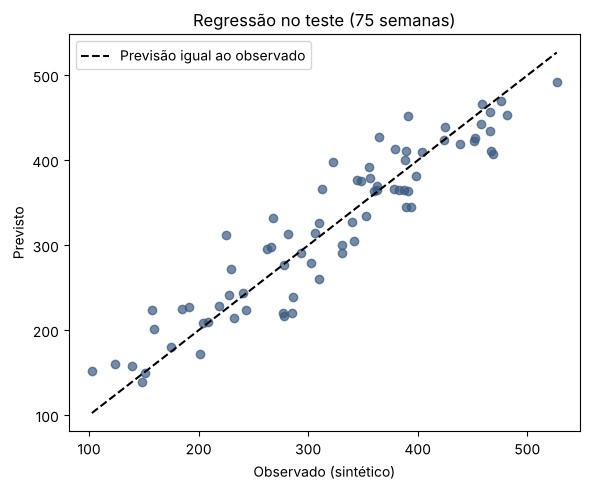

figura gravada em ../assets/regressao-residuos.png


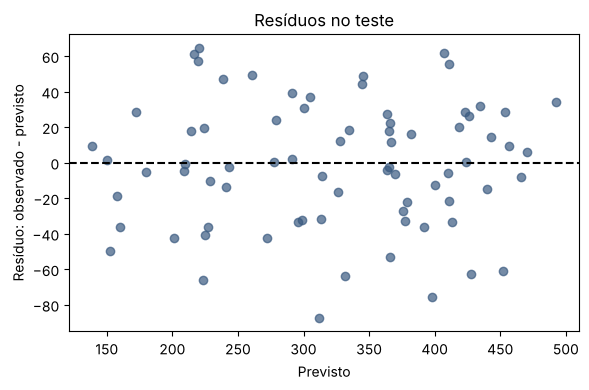

Nova previsão (500 usuários, 40 h): 303.19


In [14]:
rng_reg = np.random.default_rng(SEMENTE)
reg = pd.DataFrame({'usuarios_ativos': rng_reg.uniform(100, 1000, 300),
                    'horas_abertura': rng_reg.uniform(20, 60, 300)})
reg['emprestimos_semana'] = (30 + 0.35*reg['usuarios_ativos'] +
                           2.5*reg['horas_abertura'] + rng_reg.normal(0, 35, 300))
Xr = reg[['usuarios_ativos', 'horas_abertura']]
yr = reg['emprestimos_semana']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.25, random_state=SEMENTE)
regressor = Pipeline([('imputador', SimpleImputer(strategy='median')),
                      ('linear', LinearRegression())])
regressor.fit(Xr_tr, yr_tr)
pr = regressor.predict(Xr_te)
ref_reg = DummyRegressor(strategy='mean').fit(Xr_tr, yr_tr)
mae = mean_absolute_error(yr_te, pr)
r2 = r2_score(yr_te, pr)
mae_base = mean_absolute_error(yr_te, ref_reg.predict(Xr_te))
r2_base = r2_score(yr_te, ref_reg.predict(Xr_te))
lin = regressor.named_steps['linear']
print('Treino: %d semanas | Teste: %d semanas' % (len(Xr_tr), len(Xr_te)))
print(f'MAE teste: {mae:.2f} empréstimos/semana | MAE referência: {mae_base:.2f}')
print(f'R² teste: {r2:.4f} | R² da referência (média do treino): {r2_base:.4f}')
print('Coeficientes: usuarios_ativos %.4f (simulação: 0,35) | horas_abertura %.4f (simulação: 2,5) | intercepto %.2f (simulação: 30)'
      % (lin.coef_[0], lin.coef_[1], lin.intercept_))

plt.figure(figsize=(6, 5)); plt.scatter(yr_te, pr, marker='o', alpha=0.7, color='#3a5a80')
lim = [min(yr_te.min(), pr.min()), max(yr_te.max(), pr.max())]
plt.plot(lim, lim, 'k--', label='Previsão igual ao observado')
plt.xlabel('Observado (sintético)'); plt.ylabel('Previsto')
plt.title('Regressão no teste (75 semanas)'); plt.legend(); plt.tight_layout()
salvar('regressao-observado-previsto.png'); plt.show()

residuos = yr_te - pr
plt.figure(figsize=(6, 4)); plt.scatter(pr, residuos, color='#3a5a80', alpha=0.7)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Previsto'); plt.ylabel('Resíduo: observado - previsto')
plt.title('Resíduos no teste'); plt.tight_layout()
salvar('regressao-residuos.png'); plt.show()
print('Nova previsão (500 usuários, 40 h):', round(regressor.predict(pd.DataFrame(
    {'usuarios_ativos': [500], 'horas_abertura': [40]}))[0], 2))

## 8. Exercícios da regressão
Erros absolutos dos cinco primeiros registros do teste; retirada de um atributo por validação cruzada no treino (`KFold`, 5 partes, MAE); resumo dos resíduos; e uma extrapolação proposital para fora do domínio simulado.

In [15]:
cinco = pd.DataFrame({'real': yr_te, 'previsto': pr, 'erro_absoluto': np.abs(yr_te - pr)}).head()
print(cinco.round(2).to_string())
print('MAE desses cinco: %.2f' % cinco['erro_absoluto'].mean())

cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
def mae_cv(colunas):
    s = cross_validate(Pipeline([('imputador', SimpleImputer(strategy='median')), ('linear', LinearRegression())]),
                       Xr_tr[colunas], yr_tr, cv=cv_reg, scoring='neg_mean_absolute_error')
    return -s['test_score'].mean(), s['test_score'].std()
linhas = []
for nome, cols in [('ambos', list(Xr.columns)), ('só usuarios_ativos', ['usuarios_ativos']),
                   ('só horas_abertura', ['horas_abertura'])]:
    m, s = mae_cv(cols)
    linhas.append({'atributos': nome, 'MAE_validacao': m, 'desvio': s})
s_ref = cross_validate(DummyRegressor(strategy='mean'), Xr_tr, yr_tr, cv=cv_reg, scoring='neg_mean_absolute_error')
linhas.append({'atributos': 'referência (média)', 'MAE_validacao': -s_ref['test_score'].mean(), 'desvio': s_ref['test_score'].std()})
ablacao_reg = pd.DataFrame(linhas)
print('\n', ablacao_reg.round(2).to_string(index=False))

print('\nResíduos no teste: média %.2f | desvio %.2f | mín %.2f | máx %.2f | |resíduo| > 70: %d de %d'
      % (residuos.mean(), residuos.std(), residuos.min(), residuos.max(), (residuos.abs() > 70).sum(), len(residuos)))
print('Correlação resíduo x previsto: %.3f' % np.corrcoef(pr, residuos)[0, 1])

fora = pd.DataFrame({'usuarios_ativos': [10000, 500], 'horas_abertura': [40, 168]})
print('\nExtrapolação (fora do domínio simulado 100-1000 usuários e 20-60 h):')
print(pd.concat([fora, pd.Series(regressor.predict(fora).round(1), name='previsto')], axis=1).to_string(index=False))

       real  previsto  erro_absoluto
203  208.90    209.40           0.50
266  277.71    277.32           0.39
152  190.95    227.18          36.23
9    229.67    271.95          42.29
233  359.77    363.62           3.85
MAE desses cinco: 16.65

          atributos  MAE_validacao  desvio
             ambos          28.89    1.77
só usuarios_ativos          35.90    3.19
 só horas_abertura          83.73    5.36
referência (média)          87.22    7.74

Resíduos no teste: média -1.28 | desvio 35.47 | mín -87.24 | máx 64.59 | |resíduo| > 70: 2 de 75
Correlação resíduo x previsto: 0.027

Extrapolação (fora do domínio simulado 100-1000 usuários e 20-60 h):
 usuarios_ativos  horas_abertura  previsto
           10000              40    3609.1
             500             168     597.2


**Resultado calculado:** MAE de 28,59 empréstimos/semana contra 84,73 da referência (média do treino); R² = 0,8774 no teste (a referência, avaliada no teste, dá −0,0037, perto de zero como esperado). Os coeficientes recuperam quase os valores da simulação: 0,348 por usuário ativo (verdadeiro 0,35) e 2,297 por hora (verdadeiro 2,5), com intercepto 37,3 (verdadeiro 30). A diferença vem do ruído normal de desvio 35 e de só 225 semanas de treino.

**Exercícios:** nos cinco primeiros registros, os erros absolutos vão de 0,39 a 42,29 (média 16,65), ou seja, o MAE é uma média de erros bem desiguais. Na validação cruzada do treino, retirar `horas_abertura` piora pouco (MAE 28,9 → 35,9), e retirar `usuarios_ativos` quase iguala à referência (83,7 contra 87,2): os usuários ativos explicam a maior parte da variação, porque sua faixa (100 a 1000) multiplicada por 0,35 gera uma variação muito maior que a das horas (20 a 60 vezes 2,5). Isso é utilidade preditiva nesta simulação, não efeito causal: abrir mais horas não "causa" empréstimos nestes dados, a fórmula é que os ligou.

**Resíduos:** média −1,28, desvio 35,5, entre −87 e +65, 2 de 75 acima de 70 em módulo, correlação com o previsto de 0,03. Não há padrão (nem funil, nem curva), o que é coerente com o ruído normal e constante da simulação. Nos gráficos salvos em `../assets/`, os pontos acompanham a diagonal e os resíduos ficam espalhados em torno de zero.

**Extrapolação:** o modelo devolve 3.609 empréstimos para 10.000 usuários e 597 para 168 horas semanais. Os números saem, mas não significam nada: o modelo só viu de 100 a 1000 usuários e de 20 a 60 horas; fora disso a relação linear é uma suposição que nunca foi observada (uma biblioteca satura acervo, mesas e equipe). Um sistema que usasse o modelo deveria recusar ou marcar entradas fora do domínio de treino.

**Por que R² não é porcentagem de acertos:** R² compara a soma dos erros quadráticos do modelo com a de prever a média do conjunto avaliado; 0,877 diz que o modelo deixou 12,3% do erro quadrático da média, não que acertou 87,7% das semanas (nenhuma previsão é exatamente igual ao observado). Pode ser negativo quando o modelo é pior que a média.

## 9. Registro dos resultados desta execução
Gravo as mesmas chaves do notebook da professora e acrescento os números dos exercícios e dos meus experimentos, para que os relatórios em Markdown citem apenas valores calculados aqui.

In [16]:
resultados = {'acuracia_treino': float(acc_treino),
              'acuracia_teste': float(acc), 'acuracia_referencia': float(acc_base),
              'matriz_confusao': cm.tolist(), 'profundidade': prof,
              'mae': float(mae), 'r2': float(r2), 'mae_referencia': float(mae_base),
              'sklearn': sklearn.__version__, 'pandas': pd.__version__,
              'numpy': np.__version__, 'matplotlib': matplotlib.__version__,
              'python': sys.version.split()[0],
              'csv_igual_simulacao': csv_igual,
              'tamanhos': {'treino': int(len(X_treino)), 'teste': int(len(X_teste))},
              'comparacao_profundidade': comparacao.round(4).to_dict('records'),
              'validacao_modelo': {'media': float(melhor['acuracia_validacao_cv']), 'desvio': float(melhor['desvio_validacao_cv'])},
              'sensibilidade': float(sens), 'precisao': float(prec), 'especificidade': float(espec),
              'importancias': dict(zip(atributos, arv.feature_importances_.round(4).tolist())),
              'grade_folhas': grade.round(4).to_dict('records'),
              'ablacao': ablacao.round(4).to_dict('records'),
              'imputacao': imput.round(4).to_dict('records'),
              'vazamento': {'mediana_treino': float(mediana_treino), 'mediana_global': float(mediana_global),
                            'acuracia_teste_vazada': float(acc_vazado)},
              'poda': poda.round(4).to_dict('records'),
              'regras': regras.round(4).to_dict('records'),
              'novos': novos.to_dict('records'),
              'regressao': {'coef': lin.coef_.round(4).tolist(), 'intercepto': float(lin.intercept_),
                            'r2_referencia': float(r2_base),
                            'residuos': {'media': float(residuos.mean()), 'desvio': float(residuos.std()),
                                         'min': float(residuos.min()), 'max': float(residuos.max())},
                            'ablacao_mae_cv': ablacao_reg.round(4).to_dict('records'),
                            'extrapolacao': regressor.predict(fora).round(2).tolist()}}
with open('resultados_execucao.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=str)
print('gravado resultados_execucao.json com', len(resultados), 'chaves')

gravado resultados_execucao.json com 29 chaves


## Referências e checklist
SCIKIT-LEARN. *User Guide*. Disponível em: https://scikit-learn.org/stable/user_guide.html. Acesso em: 16 out. 2026.
SCIKIT-LEARN. *Common pitfalls and recommended practices* (data leakage). Disponível em: https://scikit-learn.org/stable/common_pitfalls.html. Acesso em: 16 out. 2026.
SCIKIT-LEARN. *Post pruning decision trees with cost complexity pruning*. Disponível em: https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html. Acesso em: 16 out. 2026.
PANDAS. *User Guide*. Disponível em: https://pandas.pydata.org/docs/user_guide/index.html. Acesso em: 16 out. 2026.
MATPLOTLIB. *Pyplot tutorial*. Disponível em: https://matplotlib.org/stable/tutorials/pyplot.html. Acesso em: 16 out. 2026.

- [x] Executei todas as células e registrei versões.
- [x] Identifiquei atributos, alvo e janela temporal.
- [x] Escolhi parâmetros apenas com o treino.
- [x] Interpretei matriz, acurácia, MAE e R².
- [x] Comparei referências e expliquei limitações.
- [x] Propus apoio humano e proteção dos dados.